# 3 · Application

Here, we will discuss one of the application from my own research work. Where we are trying to understand the co-occurence of climate signals and mobility signals. 
**Question:** Where and when do mobility signals coincide with high reference
evaporative demand or low vegetation cover?

**Study period:** 2013–2015 · **Spatial unit:** matched origin/destination zones ·
**Time unit:** half-month

| Data | Zone × period summary |
|---|---|
| METREF | Half-month cumulative ETo and mean daily ETo |
| FVC | Half-month mean FVC and change from the previous period |
| Mobility | Departures, returns or migrants; counts and population-adjusted rates |


| Step | Result |
|---|---|
| Load cube and spatial units | Confirm matching coordinates and CRS |
| `xvec.zonal_stats` | A vector data cube: one climate statistic per zone and time |
| `plot_adaptive_maps` | A single-date zonal map and a shared-scale panel for several time slices |
| Zone time series | Selected zones highlighted on a map next to their time series |
| Optional | Compare a matching mobility period with the climate map |

**Assumptions:** the cube has `time`, `lat`, and `lon` coordinates in EPSG:4326; spatial units are polygons with a unique `norm_id`; the selected variable is numeric. Change the paths and variable below to match your files.

> Start with a short time window and a regional cube. Exact extraction can take time over long records. `exactextract` uses fractional pixel coverage; the fallback `rasterize` method is faster but may omit small polygons or approximate their boundaries. xvec requires the geometries and raster coordinates to use the same CRS. [xvec zonal statistics documentation](https://xvec.readthedocs.io/en/latest/generated/xarray.DataArray.xvec.zonal_stats.html).

## 1 · Load the cube and zone polygons

This cell opens one Zarr store, reads the spatial-unit Parquet file, and limits processing to the cube footprint. If needed, set `START_DATE` and `END_DATE` to a smaller pilot period before extracting.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import xvec  # registers the .xvec accessor
import rioxarray  # needed by the exactextract backend
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from shapely.geometry import box

# Find the repository root from the current notebook directory.
REPO = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "pyproject.toml").exists())
DATA = REPO / "data"
PRODUCT = "METREF"  # e.g. METREF or FVC; must match the Zarr data variable
ZONE_FILE = DATA / "aoi" / "spatial_units_with_lat_lon.parquet"
START_DATE = None  # e.g. "2013-01-01"; None means all available dates
END_DATE = None    # e.g. "2015-12-31"

stores = sorted(p for p in (DATA / "zarr").glob("*.zarr") if (p / "zarr.json").exists())
if not stores:
    raise FileNotFoundError("No Zarr v3 store found under data/zarr; build the cube first.")
store = next((p for p in stores if PRODUCT.lower() in p.name.lower()), stores[0])
ds = xr.open_zarr(store, consolidated=False)
if PRODUCT not in ds:
    raise KeyError(f"{PRODUCT!r} not in {list(ds.data_vars)}")

# Standardize common coordinate names if this cube uses other names.
rename = {old: new for old, new in {"latitude": "lat", "longitude": "lon",
                                    "y": "lat", "x": "lon"}.items()
          if old in ds.dims or old in ds.coords}
ds = ds.rename(rename)
required = {"time", "lat", "lon"}
if not required.issubset(ds[PRODUCT].dims):
    raise ValueError(f"Expected {required} dimensions; found {ds[PRODUCT].dims}")

# Read polygon geometries from WKB Parquet (as in this tutorial's input data).
units_df = pd.read_parquet(ZONE_FILE)
if "geometry" in units_df and len(units_df) and isinstance(units_df.geometry.iloc[0], (bytes, bytearray, memoryview)):
    import shapely
    geometry = shapely.from_wkb(units_df.pop("geometry").to_numpy())
    units = gpd.GeoDataFrame(units_df, geometry=geometry, crs="EPSG:4326")
else:
    units = gpd.GeoDataFrame(units_df, geometry="geometry", crs="EPSG:4326")
if units.crs is None:
    raise ValueError("Spatial-unit CRS is missing; set the correct CRS before continuing.")
units = units.to_crs("EPSG:4326")
if "norm_id" not in units or units["norm_id"].duplicated().any():
    raise ValueError("Spatial units need a unique 'norm_id' column.")

# Trim to the time window before zonal extraction to keep the pilot manageable.
da = ds[PRODUCT].sel(time=slice(START_DATE, END_DATE))
if da.sizes.get("time", 0) == 0:
    raise ValueError("No time steps in the requested date range.")
# Include half a cell around the outer coordinate centers when selecting zones.
dx = float(np.median(np.abs(np.diff(ds.lon.values))))
dy = float(np.median(np.abs(np.diff(ds.lat.values))))
cube_footprint = box(float(ds.lon.min())-dx/2, float(ds.lat.min())-dy/2,
                     float(ds.lon.max())+dx/2, float(ds.lat.max())+dy/2)
units_in = units.loc[units.geometry.intersects(cube_footprint)].copy()
if units_in.empty:
    raise ValueError("No spatial units intersect the cube extent.")
print(f"Store: {store.name} | {dict(ds.sizes)}")
print(f"Zones intersecting cube: {len(units_in)} / {len(units)}")
print(f"Period: {pd.Timestamp(da.time.values[0]).date()} to {pd.Timestamp(da.time.values[-1]).date()}")

Store: metref_cube.zarr | {'time': 31, 'lat': 91, 'lon': 121}
Zones intersecting cube: 151 / 151
Period: 2010-01-01 to 2010-01-31


## 2 · Create zones with xvec

The spatial units become the **zones**. We pass the polygons to xvec once and ask for a spatial mean. The result is a *vector data cube*: the raster dimensions `lat`/`lon` are replaced by one `zone` dimension whose index holds the polygon geometries, and `time` is kept. The zone ID `norm_id` stays attached as a coordinate, so results can be joined back to other tables.

`exactextract` is preferred for fractional pixel coverage. If it is unavailable, the cell uses `rasterize` and reports that choice. With the fallback, cells are assigned by their centers (`all_touched=False`); small zones can have no cells, so inspect missing values.

The cube is passed to xvec with `x`/`y` dimension names, because the `exactextract` backend looks for those spatial dimension names.

In [2]:
# xvec needs matching CRS. This cube's lon/lat coordinates and zones are EPSG:4326.
zone_geometries = units_in.set_index("norm_id").geometry
try:
    import exactextract  # noqa: F401
    ZONAL_METHOD = "exactextract"
except ImportError:
    ZONAL_METHOD = "rasterize"

zonal = da.rename(lon="x", lat="y").xvec.zonal_stats(
    geometry=zone_geometries,
    x_coords="x",
    y_coords="y",
    stats="mean",
    name="zone",
    index=True,
    method=ZONAL_METHOD,
    all_touched=False,
).rename("zonal_mean").load()

n_missing = int(zonal.isnull().all("time").sum())
print("xvec method:", ZONAL_METHOD)
print(f"Zones: {zonal.sizes['zone']} | time steps: {zonal.sizes['time']} | "
      f"zones with no value at any time: {n_missing}")
zonal

/home/khizer/scientific_contributions/tutorial-repo/.venv/lib/python3.14/site-packages/dask/array/core.py:5198: PerformanceWarning: Increasing number of chunks by factor of 31
  result = blockwise(


xvec method: rasterize
Zones: 151 | time steps: 31 | zones with no value at any time: 2


<xarray.DataArray 'zonal_mean' (zone: 151, time: 31)> Size: 19kB
array([[3.3599975, 3.412    , 2.991997 , ..., 3.7359996, 3.7940001,
        3.751999 ],
       [3.2579315, 3.4821844, 3.360115 , ..., 3.7419543, 3.627012 ,
        3.3924136],
       [3.2848604, 3.4469159, 3.224019 , ..., 3.736075 , 3.6448607,
        3.5168219],
       ...,
       [3.4375005, 3.5299997, 3.0993748, ..., 3.78625  , 3.8400013,
        3.501251 ],
       [3.4919991, 3.6160004, 3.4479992, ..., 4.0700006, 4.144    ,
        3.261996 ],
       [3.1600037, 3.5825   , 3.4325035, ..., 3.9874997, 4.079999 ,
        3.3049998]], shape=(151, 31), dtype=float32)
Coordinates:
  * zone     (zone) geometry 1kB MULTIPOLYGON (((-17.1400547 14.57827377, -17...
    norm_id  (zone) object 1kB 'sen.1.1.1' 'sen.10.1.1' ... 'city-054'
  * time     (time) datetime64[ns] 248B 2010-01-01 2010-01-02 ... 2010-01-31
Indexes:
    zone     GeometryIndex (crs=EPSG:4326)
Attributes:
    long_name:  METREF
    units:      mm/day

## 3 · Zonal maps: helper and time slices

`plot_adaptive_maps` draws zonal maps from a long GeoDataFrame (one row per zone and time). Its layout adapts to the number of dates: **one date** gives a single large map, **several dates** give a near-square panel (at most `max_cols` columns). All panels share the same color limits (2nd to 98th percentile by default), so colors are comparable between dates, and one colorbar is drawn for the figure. Zones without a value are grey.

`zonal_frame` builds that GeoDataFrame straight from the xvec cube with `to_geodataframe`.

Choose the time slices with `N_SLICES` (evenly spaced over the period) or set `DATES` to your own list. Dates are matched to the nearest available time step.

In [3]:
def zonal_frame(times) -> gpd.GeoDataFrame:
    """Long GeoDataFrame (zone x time) from the xvec cube; columns: time, zone (geometry), norm_id, zonal_mean."""
    wanted = pd.DatetimeIndex(pd.to_datetime(list(times))).values
    picked = zonal.sel(time=wanted, method="nearest")
    picked = picked.isel(time=np.unique(picked.time.values, return_index=True)[1])  # drop duplicate matches
    return picked.xvec.to_geodataframe(geometry="zone", long=True).reset_index()


def plot_adaptive_maps(frame, column="zonal_mean", time_col="time", *, cmap="YlOrRd", max_cols=3,
                       quantiles=(0.02, 0.98), vmin=None, vmax=None, label=None, title=None,
                       edgecolor="#555555", linewidth=0.2):
    """One map for one date, an adaptive panel for several. Shared color scale and one colorbar."""
    times = sorted(pd.to_datetime(frame[time_col]).unique())
    n = len(times)
    lo, hi = frame[column].quantile(list(quantiles)).to_numpy()
    if not np.isfinite([lo, hi]).all():
        raise ValueError(f"No finite values in {column!r} for the selected dates.")
    vmin = lo if vmin is None else vmin
    vmax = hi if vmax is None else vmax

    ncols = min(max_cols, n if n <= 3 else int(np.ceil(np.sqrt(n))))   # 4 dates -> 2x2, 6 -> 3x2
    nrows = int(np.ceil(n / ncols))
    tile = (9, 7) if n == 1 else (4.8, 4.3)                 # a single map gets a big canvas
    fig, axes = plt.subplots(nrows, ncols, figsize=(tile[0] * ncols, tile[1] * nrows),
                             squeeze=False, layout="constrained")
    for ax, t in zip(axes.flat, times):
        part = frame.loc[pd.to_datetime(frame[time_col]) == t]
        part.plot(column=column, ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,
                  edgecolor=edgecolor, linewidth=linewidth, missing_kwds={"color": "lightgrey"})
        ax.set_title(pd.Timestamp(t).strftime("%Y-%m-%d"))
        ax.set_axis_off()
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    mappable = ScalarMappable(norm=Normalize(vmin=vmin, vmax=vmax), cmap=cmap)
    mappable.set_array([])
    fig.colorbar(mappable, ax=axes.ravel().tolist(), shrink=0.78, extend="both",
                 label=label or column)
    if title:
        fig.suptitle(title, fontsize=14)
    return fig, axes


UNITS = da.attrs.get("units", "units not recorded")
N_SLICES = 4        # evenly spaced dates over the period
DATES = None        # or e.g. ["2020-06-01", "2020-06-15", "2020-06-30"]

if DATES is None:
    positions = np.linspace(0, zonal.sizes["time"] - 1, N_SLICES).round().astype(int)
    DATES = list(zonal.time.values[np.unique(positions)])
DATES = [pd.Timestamp(d) for d in DATES]
print("Time slices:", ", ".join(d.strftime("%Y-%m-%d") for d in DATES))

Time slices: 2010-01-01, 2010-01-11, 2010-01-21, 2010-01-31


### Single zonal map

Each polygon is colored by the mean of the selected climate variable across its included cells. This is a **zonal summary**, not a higher-resolution map of the original raster.

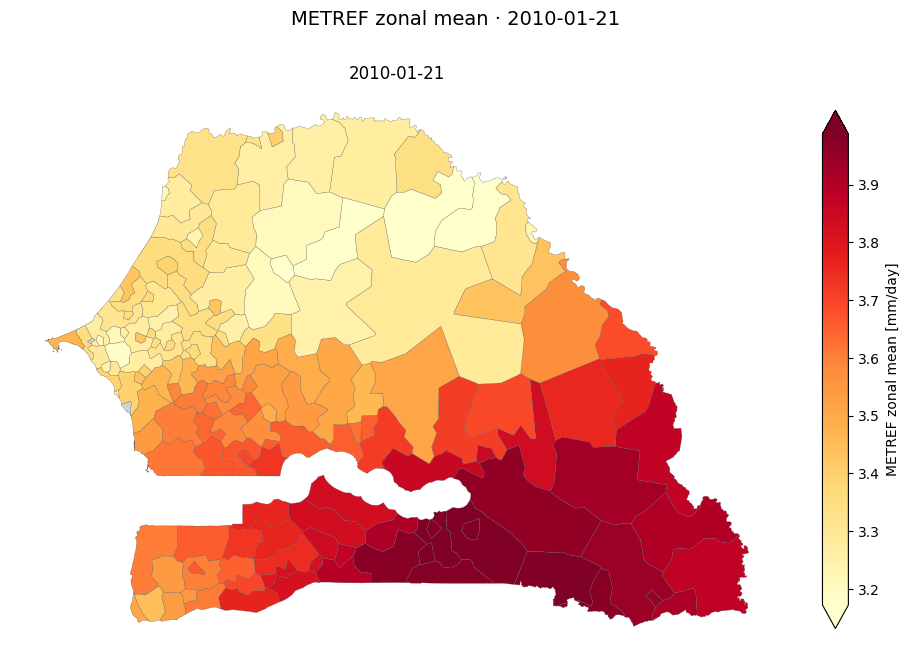

In [4]:
SINGLE_DATE = DATES[len(DATES) // 2]
plot_adaptive_maps(zonal_frame([SINGLE_DATE]), label=f"{PRODUCT} zonal mean [{UNITS}]",
                   title=f"{PRODUCT} zonal mean · {SINGLE_DATE:%Y-%m-%d}")
plt.show()

### Several time slices in one panel

The same function with all selected dates: the panel layout follows the number of dates and the color scale is shared. Use a few dates to inspect change; plotting every daily date would make an unwieldy figure.

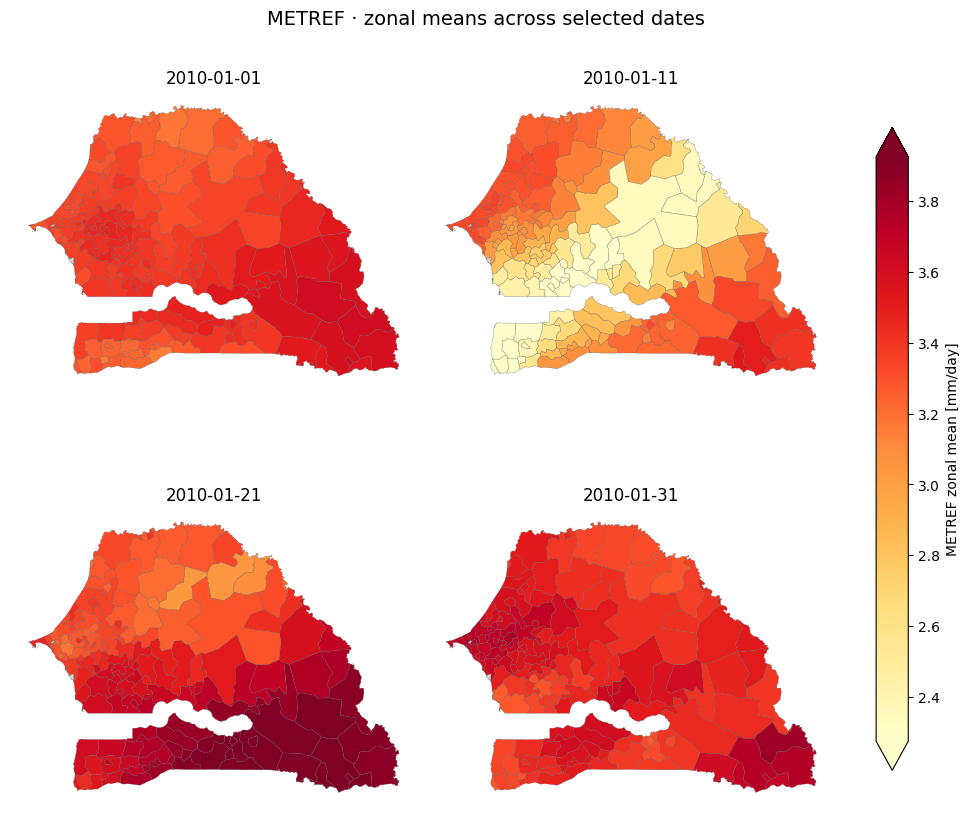

In [5]:
plot_adaptive_maps(zonal_frame(DATES), label=f"{PRODUCT} zonal mean [{UNITS}]",
                   title=f"{PRODUCT} · zonal means across selected dates")
plt.show()

## 4 · Zone time series with a locator map

Select a few zones and plot their zonal mean through time. A small map shows where the selected zones are, using the same colors as the lines. By default the zones with the lowest, median, and highest period mean are chosen; set `SELECTED_IDS` to your own `norm_id` values to override this. If the full period is long, first set `START_DATE` and `END_DATE` above to a suitable window.

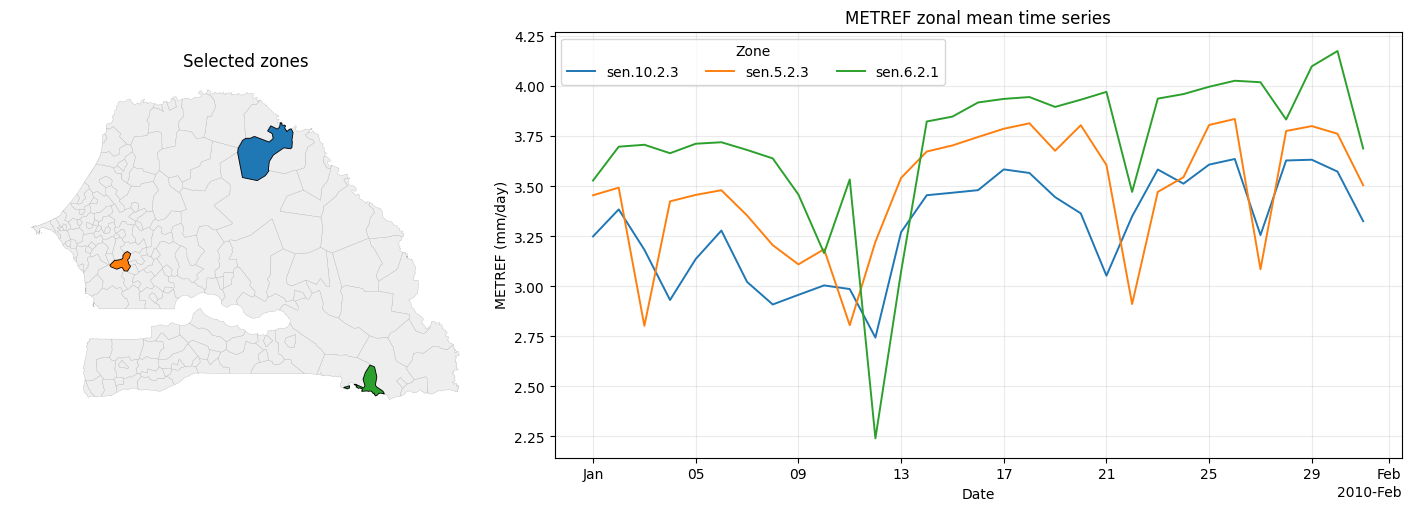

In [6]:
SELECTED_IDS = None   # e.g. ["A12", "B07", "C03"]; None = lowest, median, highest period mean

zone_ids = zonal["norm_id"].values.astype(str)
if SELECTED_IDS is None:
    period_mean = zonal.mean("time", skipna=True).values
    finite = np.flatnonzero(np.isfinite(period_mean))
    order = finite[np.argsort(period_mean[finite])]
    SELECTED_IDS = list(dict.fromkeys(zone_ids[[order[0], order[len(order) // 2], order[-1]]]))
SELECTED_IDS = [str(z) for z in SELECTED_IDS]
colors = dict(zip(SELECTED_IDS, plt.cm.tab10.colors))

fig, (ax_map, ax_ts) = plt.subplots(1, 2, figsize=(14, 5), layout="constrained",
                                    gridspec_kw={"width_ratios": [1, 1.8]})
units_in.plot(ax=ax_map, color="#eeeeee", edgecolor="#aaaaaa", linewidth=0.2)
for zone_id in SELECTED_IDS:
    units_in.loc[units_in["norm_id"].astype(str) == zone_id].plot(
        ax=ax_map, color=colors[zone_id], edgecolor="black", linewidth=0.6)
    series = zonal.isel(zone=int(np.flatnonzero(zone_ids == zone_id)[0]))
    ax_ts.plot(series.time.values, series.values, linewidth=1.4, color=colors[zone_id], label=zone_id)
ax_map.set_title("Selected zones")
ax_map.set_axis_off()
ax_ts.set_title(f"{PRODUCT} zonal mean time series")
ax_ts.set_xlabel("Date")
ax_ts.set_ylabel(f"{PRODUCT} ({UNITS})")
ax_ts.grid(alpha=0.25)
ax_ts.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax_ts.xaxis.get_major_locator()))
ax_ts.legend(title="Zone", ncols=min(3, len(SELECTED_IDS)))
plt.show()

## 5 · Optional mobility comparison

Mobility is not required for the climate zonal workflow. Set `RUN_MOBILITY = True` only when the mobility file and filters are available. Confirm that its spatial IDs and half-month dates use the same definitions as the climate data before interpreting a comparison.

In [7]:
RUN_MOBILITY = False
MOBILITY_FILE = DATA / "aoi" / "mobility_data_processed.parquet"
MOBILITY_DATE = pd.Timestamp("2015-06-01")  # use a date present in both datasets
METRIC = "rate_depart"
SUBSET, WEIGHT, SPAN = "A", "unweighted", "30days"

if RUN_MOBILITY:
    if not MOBILITY_FILE.exists():
        raise FileNotFoundError(MOBILITY_FILE)
    mob = pd.read_parquet(
        MOBILITY_FILE,
        columns=["norm_spatial_id_origin", "date", METRIC],
        filters=[("date", "==", MOBILITY_DATE), ("subset_type", "==", SUBSET),
                 ("weight_type", "==", WEIGHT), ("days_span", "==", SPAN)],
    )
    climate = zonal_frame([MOBILITY_DATE]).rename(columns={"norm_id": "zone_id"})
    movement = (mob.groupby("norm_spatial_id_origin", as_index=False)[METRIC].sum()
                  .rename(columns={"norm_spatial_id_origin": "zone_id"}))
    compare = climate.merge(movement, on="zone_id", how="left")
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
    compare.plot(column="zonal_mean", ax=axes[0], cmap="YlOrRd", legend=True,
                 edgecolor="white", linewidth=0.2, missing_kwds={"color": "lightgrey"})
    axes[0].set_title(f"{PRODUCT} zonal mean · {MOBILITY_DATE:%Y-%m-%d}")
    compare.plot(column=METRIC, ax=axes[1], cmap="Blues", legend=True,
                 edgecolor="white", linewidth=0.2,
                 missing_kwds={"color": "lightgrey", "label": "No mobility record"})
    axes[1].set_title(f"Mobility {METRIC} · {MOBILITY_DATE:%Y-%m-%d}")
    for ax in axes:
        ax.set_axis_off()
    plt.show()

## Interpretation and checks

- **CRS:** xvec does not verify that polygon and raster CRSs match; this notebook explicitly reprojects zones to EPSG:4326. Confirm the cube coordinates really are longitude/latitude degrees.
- **Pixel support:** a zone smaller than a pixel, or with only a few pixels, has an unstable mean. Check the number of zones with no value (printed after extraction) and look for grey zones on the maps.
- **Method choice:** `exactextract` accounts for fractional pixel coverage but adds a dependency and more work. `rasterize` is faster, but boundary assignment is approximate and very small polygons may return no value.
- **Variable meaning:** a mean is suitable for many continuous variables. For METREF, choose daily mean versus half-month sum according to the question and product units; do not sum a variable whose units or time semantics do not support summation.
- **Shared color scale:** the panel clips colors at the 2nd and 98th percentile. Pass `vmin`/`vmax` to `plot_adaptive_maps` for fixed limits, for example when comparing separate runs.
- **Mobility:** co-occurrence is descriptive, not evidence that climate caused a movement. Check period alignment, missing zones, privacy safeguards, and mobility filter choices.
- **Scale:** test a short time window and representative set of zones first. Process larger periods in time batches if memory, computation, or storage becomes limiting.